## Modelos 5 y 6 · Regresión Ridge y KNN para estimar propiedades de galaxias

Características visuales de imágenes DESI Legacy Imaging Surveys y redshift

Instituto Tecnológico y de Estudios Superiores de Monterrey · Equipo 24

José Florencio Maguey Peralta — A01796727  
Erick Alberto Bustos Cruz — A01378966  
Luz Copelia Minutti Pérez — A01796921

En este notebook construimos dos candidatos adicionales para estimar `log_mstar`, `log_sfr` y `d4000`. Con Ridge estudiamos cuánto podemos explicar mediante una relación lineal regularizada. Con KNN exploramos una aproximación local, basada en galaxias que presentan características similares a las de cada objeto que queremos predecir.

Conservamos las mismas galaxias, etiquetas y particiones del experimento SVR. También reutilizamos sus características visuales, el PCA, las escalas y el redshift. De esta manera, podemos comparar los regresores manteniendo fija la preparación de las entradas. Cada algoritmo produce las tres propiedades mediante un estimador con soporte para varias salidas; no combinamos sus predicciones en un ensamble.

Esta etapa termina en Validation. Integraremos ambos candidatos con ResNet50, SVR, ConvNeXt Tiny y el modelo basado en DINOv3 para completar la comparación de seis modelos. Después seleccionaremos los dos mejores, ajustaremos sus hiperparámetros y elegiremos el modelo individual final antes de evaluarlo en Test. El resultado de este notebook identifica al mejor entre Ridge y KNN; por sí solo no cierra la comparación de los seis.


## Declaración de Uso de IA

Utilizamos inteligencia artificial, a través de ChatGPT con el modelo GPT-6, como apoyo para construir el código a partir de un planteamiento general. Posteriormente, revisamos y realizamos ajustes técnicos siguiendo las indicaciones de nuestros asesores en astronomía, el Dr. Héctor Hernández Toledo y el Dr. José Antonio Vázquez Mata. Debido al nivel de especialización del problema, fue necesario adaptar el código al significado físico de las variables, las características de los datos observacionales y las correcciones propias de la disciplina. De esta manera, el uso de IA se complementó con la revisión del equipo y la orientación científica de los asesores.

1 · Entorno y resultados que reutilizamos

Abrimos este archivo con el mismo kernel de Python que utilizamos para SVR. Podemos reiniciar el kernel y ejecutar todas las celdas en orden: no necesitamos variables de otro notebook ni volver a entrenar una red convolucional. Los cálculos de Ridge y KNN se realizan en CPU.

Necesitamos conservar la carpeta de resultados de SVR, su subcarpeta de corrida y la carpeta `_caracteristicas`. Allí guardamos el protocolo, las predicciones de Validation, los modelos y el preprocesamiento ajustado con Train. El ZIP de informes por sí solo no incluye todo lo necesario. Para la comparación opcional con ResNet50 utilizamos los archivos de selección y las predicciones de Validation de A–G.

Si encontramos una única corrida completa de SVR, la recuperamos automáticamente. Si hay varias, indicamos su ruta en `CORRIDA_SVR`; no elegimos una por ser la más reciente ni por tener mejores métricas. Comprobamos la versión de scikit-learn antes de recuperar el preprocesamiento para utilizar el mismo entorno en el que lo guardamos.


In [1]:
import os
import sys
import json
import time
import hashlib
import platform
import zipfile
import importlib.util
from pathlib import Path
from datetime import datetime, timezone

requeridos = ['numpy', 'pandas', 'sklearn', 'joblib', 'matplotlib', 'threadpoolctl', 'IPython']
faltan = [x for x in requeridos if importlib.util.find_spec(x) is None]
if faltan:
    raise RuntimeError('Usa el kernel con el que ejecutamos SVR. Faltan: ' + ', '.join(faltan))
import numpy as np
import pandas as pd
import sklearn
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, FileLink


2 · Parámetros elegidos y alternativas de referencia

Fijamos una configuración inicial por algoritmo para realizar la comparación. Elegimos `alpha=1.0` en Ridge y 15 vecinos en KNN como puntos de partida, con las razones que presentamos a continuación. No contamos con registros de una búsqueda previa que demuestren que estos valores superaron a todos los demás; por eso distinguimos las elecciones que ejecutamos de las alternativas que proponemos para una revisión posterior.

| Parámetro | Valor elegido | Alternativas propuestas, no ejecutadas aquí | Motivo de nuestra elección |
|---|---|---|---|
| Regularización de Ridge, `alpha` | 1.0 | Menores: 0.01 y 0.1; mayores: 10 y 100 | Introducimos una penalización L2 positiva sobre entradas y etiquetas estandarizadas. Su efecto se evalúa con los resultados; no suponemos que sea el óptimo. |
| Solución de Ridge | `svd` | `cholesky` o métodos iterativos | Usamos una solución basada en descomposición en valores singulares, adecuada para una matriz densa de dimensión moderada. |
| Intercepto de Ridge | Sí | Sin intercepto | Permitimos un desplazamiento global; la regularización se aplica a los coeficientes. No imponemos una relación física de paso por el origen. |
| Vecinos de KNN, `k` | 15 | Menores: 5 y 10; mayores: 25 y 35 | Utilizamos un vecindario intermedio para equilibrar el detalle local y el suavizado, pendiente de evaluación. |
| Ponderación de vecinos | `distance` | `uniform` | Damos más peso a galaxias cercanas en el espacio de características. La cercanía no corresponde a separación angular en el cielo. |
| Distancia de KNN | Minkowski con `p=2`, euclidiana | `p=1`, distancia Manhattan | Adoptamos una geometría sencilla sobre las entradas estandarizadas y mantenemos una regla común para todas las propiedades. |
| Búsqueda de vecinos | `brute` | Selección automática o árboles | Calculamos vecinos exactos sin introducir otra aproximación; procesamos las consultas por lotes. |
| Hilos de CPU | 4 | 2 u 8, según recursos | Limitamos el uso del servidor. Este valor regula el cálculo, no la complejidad estadística del modelo. |
| Lote de predicción | 256 galaxias | 128 o 512 | Contenemos la memoria de trabajo al calcular distancias. No es un minibatch de entrenamiento neuronal. |
| Evaluación en Test | Desactivada | No corresponde modificarla en esta etapa | Comparamos los candidatos con Validation y dejamos la evaluación final para una etapa posterior. |

Las alternativas numéricas incluyen valores menores y mayores que los seleccionados; las opciones categóricas no tienen ese orden. Las dejamos registradas como candidatos, sin atribuirles métricas que no hemos calculado. No ejecutamos una búsqueda de hiperparámetros en este notebook: la reservamos para los dos modelos que seleccionemos después de reunir los seis candidatos.

Ridge con SVD y KNN no necesitan una semilla de entrenamiento. La aleatoriedad del PCA ya quedó fijada en el experimento SVR, donde utilizamos la semilla 42. Conservamos ese PCA y no repetimos ajustes deterministas para presentarlos como entrenamientos diferentes.


In [2]:
VERSION = 'DESI_RIDGE_KNN_1.0.0'
OBJETIVOS = ['log_mstar', 'log_sfr', 'd4000']
PARTICIONES_DESARROLLO = ('Train', 'Validation')
MODELOS = ('Ridge', 'KNN')

CARPETA_SVR = Path.home() / 'DESI_experimentos_svr' / 'modelo_02_svr_v01'
CORRIDA_SVR = ''  # Ruta completa opcional; la indicamos si hay más de una corrida terminada.
CARPETA_CACHE_SVR = ''  # Opcional si movimos la carpeta _caracteristicas del SVR.
CARPETA_AG = Path.home() / 'DESI_experimentos_mejorados' / 'desi_comparacion_A_G_v01' / '0dc2ac47a31c'
CARPETA_RESULTADOS = Path.home() / 'DESI_experimentos_ridge_knn' / 'modelos_05_06_v01'

CFG = dict(
    ridge_alpha=1.0,
    ridge_solver='svd',
    ridge_fit_intercept=True,
    knn_vecinos=15,
    knn_pesos='distance',
    knn_metrica='minkowski',
    knn_p=2,
    knn_algoritmo='brute',
    hilos_cpu=4,
    lote_prediccion=256,
    diagnostico_knn_sin_autovecino=True,
    comparar_con_ag=True,
    evaluar_test=False,
)
CONTEOS_ESPERADOS = {'Train': 7121, 'Validation': 1261, 'Test': 917}
CANDIDATOS_PROPUESTOS = {
    'ridge_alpha': [0.01, 0.1, 1.0, 10.0, 100.0],
    'knn_vecinos': [5, 10, 15, 25, 35],
    'knn_pesos': ['uniform', 'distance'],
    'knn_p': [1, 2],
}
# Estos candidatos quedan documentados; esta etapa no ejecuta una búsqueda.
if CFG['evaluar_test']:
    raise ValueError('Este notebook termina en Validation; evaluar_test debe ser False.')
print('Python:', sys.executable)
print('scikit-learn:', sklearn.__version__)
print('Candidatos individuales: Ridge y KNN. Test desactivado.')


Python: /home/a01796921/katachi-env/bin/python
scikit-learn: 1.9.1
Candidatos individuales: Ridge y KNN. Test desactivado.


In [3]:
def json_compatible(x):
    if isinstance(x, Path): return str(x)
    if isinstance(x, np.ndarray): return x.tolist()
    if isinstance(x, np.generic): return x.item()
    raise TypeError(type(x).__name__)


def firma(objeto):
    texto = json.dumps(objeto, sort_keys=True, ensure_ascii=False, separators=(',', ':'),
                       allow_nan=False, default=json_compatible)
    return hashlib.sha256(texto.encode()).hexdigest()


def sha_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(4 * 1024 * 1024), b''): h.update(bloque)
    return h.hexdigest()


def escribir_json(objeto, ruta):
    ruta = Path(ruta); ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_name(ruta.name + '.tmp')
    temporal.write_text(json.dumps(objeto, ensure_ascii=False, indent=2, allow_nan=False,
                                   default=json_compatible), encoding='utf-8')
    os.replace(temporal, ruta)


def escribir_csv(tabla, ruta):
    ruta = Path(ruta); ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_name(ruta.name + '.tmp')
    tabla.to_csv(temporal, index=False, encoding='utf-8-sig')
    os.replace(temporal, ruta)


def comprobar_sello(ruta, identidad):
    ruta = Path(ruta)
    meta = json.loads(ruta.with_suffix('.json').read_text())
    if meta.get('identidad') != identidad or meta.get('sha256') != sha_archivo(ruta):
        raise ValueError('Firma o contenido inconsistente: ' + str(ruta))
    return meta['sha256']


def resolver_svr(base, exacta=''):
    requeridos = ['protocolo_svr.json', 'preprocesamiento.joblib', 'preprocesamiento.json',
                  'modelo_svr_inicial.joblib', 'modelo_svr_inicial.json', 'muestra_SVR.csv',
                  'predicciones_Validation.csv', 'metricas_Validation.csv', 'registro_candidato_svr.json']
    def completa(p): return all((p / x).is_file() for x in requeridos)
    if exacta:
        p = Path(exacta).expanduser().resolve()
        if not completa(p):
            raise FileNotFoundError('CORRIDA_SVR no contiene la corrida completa. Faltan: '
                                    + ', '.join(x for x in requeridos if not (p / x).is_file()))
        return p
    base = Path(base).expanduser().resolve()
    candidatas = [base] if completa(base) else sorted(p.parent for p in base.glob('*/protocolo_svr.json') if completa(p.parent))
    if len(candidatas) != 1:
        raise RuntimeError('Encontramos ' + str(len(candidatas)) + ' corridas SVR completas. '
                           'Indica CORRIDA_SVR con la ruta exacta; no seleccionamos por fecha ni desempeño.\n'
                           + '\n'.join(map(str, candidatas)))
    return candidatas[0]


def cargar_fuente_svr(carpeta, conteos):
    carpeta = Path(carpeta)
    documento = json.loads((carpeta / 'protocolo_svr.json').read_text())
    identidad = firma(documento)
    registro = json.loads((carpeta / 'registro_candidato_svr.json').read_text())
    if registro['identidad'] != identidad:
        raise ValueError('La identidad de SVR no coincide con su protocolo.')
    hash_modelo = comprobar_sello(carpeta / 'modelo_svr_inicial.joblib', identidad)
    if registro['modelo_sha256'] != hash_modelo:
        raise ValueError('El registro de SVR corresponde a otros pesos.')
    hash_pre = comprobar_sello(carpeta / 'preprocesamiento.joblib', identidad)
    version_origen = documento['entorno']['sklearn']
    if sklearn.__version__ != version_origen:
        raise RuntimeError(f'Usa el mismo kernel que SVR: scikit-learn {version_origen}; actual {sklearn.__version__}.')
    extractor = documento['extractor']
    if (extractor.get('arquitectura') != 'ResNet50' or extractor.get('pesos') != 'ImageNet1K_V1'
        or extractor.get('entrenamiento_extractor') is not False
        or extractor.get('caracteristicas') != 2048
        or extractor.get('representacion') != 'RGB_Lupton_AG_300'):
        raise ValueError('Esperábamos el extractor RGB fijo de ImageNet utilizado en SVR.')
    datos = pd.DataFrame(documento['entradas'])
    if (datos.empty or datos.mangaid.isna().any() or datos.mangaid.duplicated().any()
        or not datos.particion.isin(conteos).all()):
        raise ValueError('Identificadores o particiones inconsistentes en SVR.')
    datos['mangaid'] = datos.mangaid.astype(str)
    datos = datos.sort_values('mangaid').reset_index(drop=True)
    if datos.particion.value_counts().to_dict() != conteos:
        raise ValueError('La muestra no conserva los conteos esperados: ' + str(datos.particion.value_counts().to_dict()))
    if not np.isfinite(datos[[*OBJETIVOS, 'redshift']].to_numpy(float)).all() or datos.redshift.le(0).any():
        raise ValueError('Etiquetas o redshift no utilizables; no eliminamos galaxias automáticamente.')
    muestra = pd.read_csv(carpeta / 'muestra_SVR.csv', dtype={'mangaid': str})
    if muestra.mangaid.isna().any() or muestra.mangaid.duplicated().any() or set(muestra.mangaid) != set(datos.mangaid):
        raise ValueError('La muestra CSV y el protocolo no corresponden a las mismas galaxias.')
    muestra = muestra.set_index('mangaid').loc[datos.mangaid]
    if (not np.array_equal(muestra.particion.to_numpy(), datos.particion.to_numpy())
        or not np.allclose(muestra[[*OBJETIVOS, 'redshift']], datos[[*OBJETIVOS, 'redshift']], atol=1e-8, rtol=0)):
        raise ValueError('Cambiaron las etiquetas, particiones o redshift de la muestra.')
    # Deserializamos solamente el preprocesamiento propio de nuestra corrida, tras verificar su sello.
    pre = joblib.load(carpeta / 'preprocesamiento.joblib')
    train = datos.loc[datos.particion.eq('Train')]
    if pre['ids_train_sha256'] != firma(train.mangaid.tolist()):
        raise ValueError('El preprocesamiento no se ajustó con los mismos ID de Train en el mismo orden.')
    escala_y = pre['escala_y']
    if (np.any(escala_y.var_ <= 0) or np.any(np.asarray(escala_y.n_samples_seen_) != len(train))
        or not np.allclose(escala_y.mean_, train[OBJETIVOS].mean(), atol=1e-8, rtol=0)
        or not np.allclose(escala_y.scale_, train[OBJETIVOS].std(ddof=0), atol=1e-8, rtol=0)):
        raise ValueError('Las escalas de las etiquetas no corresponden a Train.')
    visual = pre['procesador'].named_transformers_['imagen']
    pca = visual.named_steps['pca']
    if (pca.n_samples_ != len(train) or int(pca.n_components_) != documento['configuracion']['componentes_pca']
        or pca.whiten or pre['procesador'].n_features_in_ != 2049):
        raise ValueError('El PCA o las dimensiones no coinciden con el preprocesamiento de SVR.')
    for escalador in [visual.named_steps['escala_visual'], visual.named_steps['escala_componentes'],
                      pre['procesador'].named_transformers_['redshift']]:
        if np.any(np.asarray(escalador.n_samples_seen_) != len(train)):
            raise ValueError('Una escala de entrada no se ajustó con el número esperado de galaxias de Train.')
    origen = dict(identidad_svr=identidad, protocolo_sha256=sha_archivo(carpeta / 'protocolo_svr.json'),
                  preprocesamiento_sha256=hash_pre, modelo_svr_sha256=hash_modelo,
                  carpeta_svr=str(carpeta), extractor=extractor)
    return datos, documento, pre, origen


3 · Recuperación de la muestra y control de identidad

Recuperamos la definición de la muestra del protocolo SVR y la contrastamos con su CSV. Comprobamos los identificadores, las particiones, las etiquetas y el redshift. Conservamos 7 121 galaxias en Train, 1 261 en Validation y 917 identificadores en la partición Test; no reasignamos objetos ni excluimos casos a partir de sus errores.

También revisamos las huellas de los archivos y verificamos que las escalas de las etiquetas correspondan a las medias y desviaciones poblacionales de Train. Mantenemos las definiciones de `log_mstar`, `log_sfr` y `d4000` del catálogo neuronal. No cambiamos las etiquetas ni añadimos nuevas correcciones astronómicas en esta etapa.

Leemos la definición de las tres particiones para verificar su consistencia, pero solo recuperamos características y calculamos predicciones de Train y Validation. No cargamos características ni resultados de Test. Los archivos originales de SVR y A–G se utilizan únicamente como fuentes de lectura.


In [4]:
FUENTE_SVR = resolver_svr(CARPETA_SVR, CORRIDA_SVR)
MUESTRA, DOCUMENTO_SVR, PREPROCESAMIENTO, ORIGEN = cargar_fuente_svr(FUENTE_SVR, CONTEOS_ESPERADOS)
TABLAS = {p: MUESTRA.loc[MUESTRA.particion.eq(p)].reset_index(drop=True) for p in PARTICIONES_DESARROLLO}
CACHE_SVR = (Path(CARPETA_CACHE_SVR).expanduser() if CARPETA_CACHE_SVR
             else FUENTE_SVR.parent / '_caracteristicas') / firma(DOCUMENTO_SVR['extractor'])[:16]
display(MUESTRA.groupby('particion').size().rename('galaxias').to_frame())
print('Corrida SVR:', FUENTE_SVR)
print('Leemos la definición de las tres particiones; procesamos únicamente Train y Validation.')


,galaxias
particion,
Test,917
Train,7121
Validation,1261


Corrida SVR: /home/a01796921/DESI_experimentos_svr/modelo_02_svr_v01/74b206b7ef8e6666
Leemos la definición de las tres particiones; procesamos únicamente Train y Validation.


4 · Preparación compartida de las entradas

En SVR obtuvimos 2048 características por imagen mediante ResNet50 con los pesos originales de ImageNet1K V1. Mantuvimos el extractor congelado y utilizamos RGB de Lupton de 300 × 300 píxeles. Aquí recuperamos exactamente esas características desde la caché, sin extraerlas de nuevo ni utilizar los pesos ajustados de la variante E.

Reutilizamos la siguiente preparación, ajustada exclusivamente con Train:

| Elemento | Tratamiento que conservamos | Razón |
|---|---|---|
| Características visuales | Estandarización por componente | Conservamos la escala de entrada utilizada en SVR. |
| Reducción visual | PCA; en el diseño original, 128 componentes | Mantenemos la misma representación para comparar los regresores. Recuperamos y mostramos la dimensión efectiva guardada. |
| Componentes de PCA | Estandarización de sus puntuaciones | Conservamos el tratamiento de las distancias y la regularización utilizado en la preparación original. |
| Redshift | Estandarización independiente y concatenación al final | Incorporamos esta información sin incluirla en la reducción de las características visuales. |
| Etiquetas | Media y desviación de Train | Entrenamos en una escala comparable y devolvemos las predicciones a sus unidades originales. |

Con 128 componentes visuales y redshift obtenemos 129 entradas por galaxia. Como alternativas de dimensión podríamos estudiar 64 o 256 componentes, pero no las evaluamos aquí porque queremos mantener las entradas del SVR. Mostramos la varianza visual retenida para describir la reducción; no la interpretamos como una medida de la información predictiva conservada.

La estandarización evita diferencias debidas únicamente a las unidades numéricas, pero no garantiza la misma influencia conjunta del bloque visual y del redshift en KNN. La distancia depende de todos los componentes y puede perder capacidad de distinguir vecinos si muchas dimensiones aportan poca información relevante.


In [5]:
def recuperar_entradas(tabla, particion, documento, raiz_cache):
    if particion not in PARTICIONES_DESARROLLO or not tabla.particion.eq(particion).all():
        raise ValueError('Solo recuperamos características de Train o Validation.')
    tamano = int(documento['configuracion']['bloque_cache'])
    if tamano <= 0: raise ValueError('Tamaño de bloque inválido.')
    valores, fuentes = [], []
    for inicio in range(0, len(tabla), tamano):
        parte = tabla.iloc[inicio:inicio + tamano]
        identidad = firma(dict(extractor=documento['extractor'],
                              imagenes=parte[['mangaid','rgb_sha256']].to_dict('records')))
        ruta = Path(raiz_cache) / particion / (f'bloque_{inicio:06d}_' + identidad[:12] + '.npz')
        if not ruta.is_file() or not ruta.with_suffix('.json').is_file():
            raise FileNotFoundError('Falta una caché de SVR: ' + str(ruta)
                                    + '. Recupera su carpeta _caracteristicas o ejecuta la extracción del notebook SVR.')
        sello = comprobar_sello(ruta, identidad)
        with np.load(ruta, allow_pickle=False) as cache:
            ids = cache['ids'].astype(str).tolist()
            f = cache['caracteristicas'].copy()
        if ids != parte.mangaid.tolist() or f.shape != (len(parte), 2048) or not np.isfinite(f).all():
            raise ValueError('Características o ID inconsistentes: ' + str(ruta))
        valores.append(f)
        fuentes.append(dict(particion=particion, archivo=str(ruta), sha256=sello, identidad=identidad))
    visual = np.concatenate(valores, axis=0)
    # Reproducimos la conversión float32 del redshift usada al construir X en SVR.
    entrada = np.column_stack([visual, tabla.redshift.to_numpy(dtype=np.float32)])
    return np.ascontiguousarray(entrada, dtype=np.float64), fuentes


def transformar_entradas(entrada, pre, particion):
    if particion not in PARTICIONES_DESARROLLO:
        raise ValueError('Test no se transforma en esta etapa.')
    if entrada.ndim != 2 or entrada.shape[1] != 2049 or not np.isfinite(entrada).all():
        raise ValueError('La entrada debe contener 2048 características y un redshift finitos.')
    z = np.ascontiguousarray(pre['procesador'].transform(entrada), dtype=np.float64)
    if not np.isfinite(z).all(): raise ValueError('El preprocesamiento produjo valores no finitos.')
    return z


In [6]:
X, Z, FUENTES_CACHE = {}, {}, []
with threadpool_limits(limits=CFG['hilos_cpu']):
    for particion in PARTICIONES_DESARROLLO:
        X[particion], fuentes = recuperar_entradas(TABLAS[particion], particion, DOCUMENTO_SVR, CACHE_SVR)
        FUENTES_CACHE.extend(fuentes)
        Z[particion] = transformar_entradas(X[particion], PREPROCESAMIENTO, particion)
ESCALA_Y = PREPROCESAMIENTO['escala_y']
Y_TRAIN = TABLAS['Train'][OBJETIVOS].to_numpy(dtype=np.float64)
Y_NORMAL = ESCALA_Y.transform(Y_TRAIN)
visual = PREPROCESAMIENTO['procesador'].named_transformers_['imagen']
if not np.allclose(visual.named_steps['escala_visual'].mean_, X['Train'][:, :2048].mean(axis=0), atol=1e-8, rtol=1e-7):
    raise ValueError('Las características de Train no corresponden al escalador visual guardado.')
pca = visual.named_steps['pca']
if any(z.shape[1] != int(pca.n_components_) + 1 for z in Z.values()):
    raise ValueError('Dimensión inesperada después de PCA y redshift.')
print('Matrices preparadas:', {p: z.shape for p,z in Z.items()})
print('Varianza visual retenida por PCA en Train:', f'{pca.explained_variance_ratio_.sum():.4f}')
print('Reutilizamos escalas y PCA; no volvimos a ajustarlos.')


Matrices preparadas: {'Train': (7121, 129), 'Validation': (1261, 129)}
Varianza visual retenida por PCA en Train: 0.8693
Reutilizamos escalas y PCA; no volvimos a ajustarlos.


In [7]:
def validar_configuracion(cfg, n_train):
    if cfg.get('evaluar_test', False): raise ValueError('Test debe permanecer desactivado.')
    if not np.isfinite(cfg['ridge_alpha']) or cfg['ridge_alpha'] <= 0:
        raise ValueError('Ridge requiere alpha positivo.')
    if type(cfg['knn_vecinos']) is not int or not 1 <= cfg['knn_vecinos'] < n_train:
        raise ValueError('k debe ser un entero positivo menor que el número de galaxias de Train.')
    if cfg['knn_pesos'] not in ('uniform','distance') or cfg['knn_p'] not in (1,2):
        raise ValueError('Usamos pesos uniform o distance y p igual a 1 o 2.')
    if cfg['ridge_solver'] != 'svd' or cfg['knn_algoritmo'] != 'brute' or cfg['knn_metrica'] != 'minkowski':
        raise ValueError('Esta implementación utiliza Ridge SVD y KNN brute/Minkowski.')
    if any(type(cfg[k]) is not int or cfg[k] < 1 for k in ['hilos_cpu','lote_prediccion']):
        raise ValueError('Los tamaños de procesamiento deben ser enteros positivos.')


def ajustar_modelo(nombre, z_train, y_normal, pre, cfg, salida, identidad, ids_train):
    if nombre not in MODELOS: raise ValueError('Modelo no reconocido.')
    validar_configuracion(cfg, len(ids_train))
    if (z_train.shape[0] != len(ids_train) or y_normal.shape != (len(ids_train),3)
        or len(set(ids_train)) != len(ids_train)
        or not np.isfinite(z_train).all() or not np.isfinite(y_normal).all()):
        raise ValueError('Datos de entrenamiento inconsistentes.')
    carpeta = Path(salida) / nombre; carpeta.mkdir(parents=True, exist_ok=True)
    ruta = carpeta / 'modelo.joblib'
    import fcntl
    with open(carpeta / 'ajuste.lock', 'a') as bloqueo:
        try: fcntl.flock(bloqueo, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError: raise RuntimeError('Otra sesión está ajustando ' + nombre)
        if ruta.exists():
            comprobar_sello(ruta, identidad)
            paquete = joblib.load(ruta)
            if paquete['nombre'] != nombre or paquete['ids_train_sha256'] != firma(ids_train):
                raise ValueError('El modelo guardado pertenece a otro entrenamiento.')
            print('Recuperamos', nombre, 'sin volver a ajustarlo.')
            return paquete
        estimador = (Ridge(alpha=cfg['ridge_alpha'], solver=cfg['ridge_solver'],
                           fit_intercept=cfg['ridge_fit_intercept']) if nombre=='Ridge' else
                     KNeighborsRegressor(n_neighbors=cfg['knn_vecinos'], weights=cfg['knn_pesos'],
                                         algorithm=cfg['knn_algoritmo'], metric=cfg['knn_metrica'],
                                         p=cfg['knn_p'], n_jobs=cfg['hilos_cpu']))
        inicio = time.monotonic()
        with threadpool_limits(limits=cfg['hilos_cpu']): estimador.fit(z_train, y_normal)
        paquete = dict(nombre=nombre, estimador=estimador, procesador=pre['procesador'],
                       escala_y=pre['escala_y'], objetivos=OBJETIVOS.copy(), configuracion=dict(cfg),
                       identidad=identidad, ids_train_sha256=firma(ids_train),
                       segundos_ajuste=time.monotonic()-inicio, sklearn=sklearn.__version__)
        temporal = ruta.with_name(ruta.name+'.tmp')
        joblib.dump(paquete, temporal, compress=3); os.replace(temporal, ruta)
        escribir_json(dict(identidad=identidad, sha256=sha_archivo(ruta)), ruta.with_suffix('.json'))
        print(f'{nombre} ajustado con {len(ids_train):,} galaxias y {z_train.shape[1]} entradas.')
        return paquete


def predecir_modelo(paquete, z, particion):
    if particion not in PARTICIONES_DESARROLLO:
        raise ValueError('Solo predecimos Train y Validation.')
    if z.ndim != 2 or z.shape[1] != paquete['estimador'].n_features_in_ or not np.isfinite(z).all():
        raise ValueError('Matriz de predicción incompatible.')
    lote = paquete['configuracion']['lote_prediccion']
    with threadpool_limits(limits=paquete['configuracion']['hilos_cpu']):
        normal = np.concatenate([paquete['estimador'].predict(z[i:i+lote]) for i in range(0,len(z),lote)])
    pred = paquete['escala_y'].inverse_transform(normal)
    if pred.shape != (len(z),3) or not np.isfinite(pred).all():
        raise ValueError('Predicciones no utilizables.')
    return pred


def diagnostico_sin_autovecino(paquete, z_train, y_normal, ids_train):
    if paquete['nombre'] != 'KNN' or paquete['ids_train_sha256'] != firma(ids_train):
        raise ValueError('El diagnóstico necesita KNN y sus ID originales de Train.')
    if z_train.shape[0] != len(ids_train) or y_normal.shape != (len(ids_train),3):
        raise ValueError('Dimensiones inconsistentes en el diagnóstico de vecinos.')
    cfg = paquete['configuracion']; k = cfg['knn_vecinos']; lote = cfg['lote_prediccion']
    pred = np.empty_like(y_normal, dtype=float)
    with threadpool_limits(limits=cfg['hilos_cpu']):
        for inicio in range(0,len(z_train),lote):
            dist, indices = paquete['estimador'].kneighbors(z_train[inicio:inicio+lote], n_neighbors=k+1)
            for j,(dd,ii) in enumerate(zip(dist,indices)):
                conservar = ii != inicio+j
                dd, ii = dd[conservar][:k], ii[conservar][:k]
                if len(ii) != k: raise ValueError('No hay suficientes vecinos distintos del objeto consultado.')
                if cfg['knn_pesos']=='uniform': pesos=np.ones(k)
                elif np.any(dd==0): pesos=(dd==0).astype(float)
                else: pesos=1.0/dd
                pred[inicio+j] = np.average(y_normal[ii],axis=0,weights=pesos)
    return paquete['escala_y'].inverse_transform(pred)


In [8]:
validar_configuracion(CFG, len(TABLAS['Train']))
PROTOCOLO = dict(version=VERSION, configuracion=CFG, candidatos_propuestos_no_ejecutados=CANDIDATOS_PROPUESTOS,
                 origen=ORIGEN, fuentes_cache=FUENTES_CACHE,
                 entradas_desarrollo=pd.concat([TABLAS[p] for p in PARTICIONES_DESARROLLO]).to_dict('records'),
                 entorno=dict(python=platform.python_version(), numpy=np.__version__, sklearn=sklearn.__version__,
                              joblib=joblib.__version__), etapa='Comparación inicial de dos algoritmos; sin ajuste de hiperparámetros')
IDENTIDAD = firma(PROTOCOLO)
SALIDA = CARPETA_RESULTADOS / IDENTIDAD[:16]
SALIDA.mkdir(parents=True, exist_ok=True)
escribir_json(PROTOCOLO, SALIDA / 'protocolo_Ridge_KNN.json')
escribir_csv(MUESTRA[['mangaid','particion','redshift',*OBJETIVOS]], SALIDA / 'muestra_comun.csv')
print('Resultados:', SALIDA)


Resultados: /home/a01796921/DESI_experimentos_ridge_knn/modelos_05_06_v01/32c9957a9ea988c4


5 · Modelo 5: regresión Ridge

Ajustamos una relación lineal entre las entradas preparadas y cada una de las tres propiedades estandarizadas. Añadimos una penalización L2 sobre los coeficientes para limitar soluciones con pesos excesivamente grandes. El parámetro `alpha` controla esa penalización; su valor no representa una incertidumbre astronómica.

Utilizamos `alpha=1.0`, solución SVD e intercepto. Aunque el preprocesamiento incluye un extractor convolucional, la relación que aprende Ridge es lineal respecto del vector que recibe. Por ello presentamos este candidato como Ridge sobre características visuales fijas y redshift, no como una regresión aplicada directamente a los píxeles.

Guardamos el estimador junto con el preprocesamiento y las escalas de las etiquetas. Si ejecutamos de nuevo el notebook con la misma configuración y archivos de origen, recuperamos el modelo terminado después de comprobar su identidad.


In [9]:
PAQUETE_RIDGE = ajustar_modelo('Ridge', Z['Train'], Y_NORMAL, PREPROCESAMIENTO, CFG,
                              SALIDA, IDENTIDAD, TABLAS['Train'].mangaid.tolist())
print('Alpha:', PAQUETE_RIDGE['estimador'].alpha, '| Solver:', PAQUETE_RIDGE['estimador'].solver)


Recuperamos Ridge sin volver a ajustarlo.
Alpha: 1.0 | Solver: svd


6 · Modelo 6: regresión por vecinos más cercanos

Con KNN conservamos las entradas y etiquetas de Train para buscar las 15 galaxias más cercanas a cada consulta en el espacio preparado. Estimamos las tres propiedades mediante un promedio ponderado de sus etiquetas, dando mayor peso a las distancias pequeñas. Si encontramos vecinos a distancia exactamente cero, utilizamos esos vecinos para evitar una división por cero.

Esta aproximación nos permite estudiar relaciones locales sin imponer una función lineal global. Sus resultados dependen de la representación y de la utilidad de la distancia para identificar galaxias comparables. El promedio se realiza sobre etiquetas de vecinos, no sobre predicciones de modelos independientes, por lo que KNN no constituye un ensamble.

Elegimos 15 vecinos y ponderación por distancia como configuración inicial. No afirmamos que sean los mejores valores antes de evaluar. Guardamos este estimador por separado de Ridge y conservamos sus propias predicciones, métricas y registro de configuración.


In [10]:
PAQUETE_KNN = ajustar_modelo('KNN', Z['Train'], Y_NORMAL, PREPROCESAMIENTO, CFG,
                            SALIDA, IDENTIDAD, TABLAS['Train'].mangaid.tolist())
print('Vecinos:', PAQUETE_KNN['estimador'].n_neighbors, '| Pesos:', PAQUETE_KNN['estimador'].weights)


Recuperamos KNN sin volver a ajustarlo.
Vecinos: 15 | Pesos: distance


7 · Evaluación de los dos candidatos

Calculamos MAE, RMSE, sesgo y R² en la escala original de las etiquetas. Definimos el sesgo como predicción menos referencia; un promedio cercano a cero puede coexistir con errores individuales grandes. Expresamos los errores de masa y SFR en dex y los de D4000 en unidades adimensionales.

Para comparar conjuntamente las tres propiedades usamos `MSE_normalizado = (RMSE / desviacion_Train)²` y promediamos sus tres valores. Seleccionamos el menor promedio en Validation. No utilizamos el R² medio ni un resultado aislado de una propiedad para cambiar esa regla.

Las métricas de Train describen el ajuste sobre las galaxias utilizadas para construir los modelos. En KNN con ponderación por distancia, una galaxia de Train suele encontrarse a sí misma y puede obtener un error prácticamente nulo. Por ello interpretamos ese resultado junto con Validation y con el diagnóstico adicional de la siguiente sección.


In [11]:
def calcular_metricas(tabla, pred, nombre, escalas, evaluacion=None):
    if (tabla.empty or tabla.particion.nunique()!=1
        or tabla.particion.iloc[0] not in PARTICIONES_DESARROLLO
        or tabla.mangaid.isna().any() or tabla.mangaid.duplicated().any()):
        raise ValueError('Evaluamos galaxias únicas de Train o Validation.')
    y = tabla[OBJETIVOS].to_numpy(float); pred = np.asarray(pred,float)
    escalas = np.asarray(escalas,float)
    if (pred.shape != y.shape or len(tabla)<2 or not np.isfinite(pred).all()
        or not np.isfinite(y).all() or escalas.shape!=(3,)
        or not np.isfinite(escalas).all() or np.any(escalas<=0)):
        raise ValueError('Datos no utilizables para las métricas.')
    evaluacion = evaluacion or tabla.particion.iloc[0]
    datos=tabla[['mangaid','particion','redshift',*OBJETIVOS]].copy()
    datos['modelo']=nombre; datos['evaluacion']=evaluacion
    filas=[]
    for j,objetivo in enumerate(OBJETIVOS):
        error=pred[:,j]-y[:,j]; mse=float(np.mean(error**2))
        den=float(np.sum((y[:,j]-y[:,j].mean())**2))
        datos['pred_'+objetivo]=pred[:,j];datos['residuo_'+objetivo]=error
        filas.append(dict(modelo=nombre,particion=tabla.particion.iloc[0],evaluacion=evaluacion,
            objetivo=objetivo,unidad='adimensional' if objetivo=='d4000' else 'dex',n=len(tabla),
            MAE=float(np.abs(error).mean()),RMSE=float(np.sqrt(mse)),sesgo=float(error.mean()),
            R2=1-float(np.sum(error**2))/den if den>0 else np.nan,
            MSE_normalizado=mse/(escalas[j]**2)))
    return datos,pd.DataFrame(filas)


def ordenar_modelos(metricas):
    val=metricas.loc[metricas.particion.eq('Validation') & metricas.evaluacion.eq('Validation')].copy()
    if val.empty or val.duplicated(['modelo','objetivo']).any():
        raise ValueError('No hay una evaluación única por modelo y propiedad.')
    if not np.isfinite(val.MSE_normalizado).all() or val.MSE_normalizado.lt(0).any():
        raise ValueError('El criterio global no es válido.')
    if val.n.nunique()!=1: raise ValueError('Los modelos no tienen el mismo número de galaxias de Validation.')
    for _,g in val.groupby('modelo'):
        if set(g.objetivo)!=set(OBJETIVOS) or len(g)!=3:
            raise ValueError('Cada modelo debe tener las tres propiedades.')
    ranking=val.groupby('modelo',as_index=False).MSE_normalizado.mean()
    return ranking.rename(columns={'MSE_normalizado':'MSE_normalizado_global'}).sort_values(
        ['MSE_normalizado_global','modelo'],kind='stable').reset_index(drop=True)


def validar_predicciones_guardadas(pred, referencia):
    necesarias={'mangaid','particion','redshift',*OBJETIVOS,*['pred_'+y for y in OBJETIVOS]}
    if not necesarias.issubset(pred.columns): raise ValueError('Faltan columnas en las predicciones guardadas.')
    if (pred.mangaid.isna().any() or pred.mangaid.duplicated().any()
        or set(pred.mangaid)!=set(referencia.mangaid) or not pred.particion.eq('Validation').all()):
        raise ValueError('Las predicciones no contienen las mismas galaxias de Validation.')
    pred=pred.set_index('mangaid').loc[referencia.mangaid].reset_index()
    if not np.allclose(pred[[*OBJETIVOS,'redshift']],referencia[[*OBJETIVOS,'redshift']],atol=1e-6,rtol=0):
        raise ValueError('Las etiquetas o redshifts de la referencia no coinciden.')
    if not np.isfinite(pred[['pred_'+y for y in OBJETIVOS]].to_numpy(float)).all():
        raise ValueError('La referencia contiene predicciones no finitas.')
    return pred


In [12]:
PAQUETES={'Ridge':PAQUETE_RIDGE,'KNN':PAQUETE_KNN}
PREDICCIONES={}; filas=[]; tiempos=[]
for nombre,paquete in PAQUETES.items():
    for particion in PARTICIONES_DESARROLLO:
        inicio=time.monotonic()
        pred=predecir_modelo(paquete,Z[particion],particion)
        tiempos.append(dict(modelo=nombre,particion=particion,segundos_prediccion=time.monotonic()-inicio))
        datos,met=calcular_metricas(TABLAS[particion],pred,nombre,ESCALA_Y.scale_)
        PREDICCIONES[(nombre,particion)]=datos;filas.append(met)
        escribir_csv(datos,SALIDA/nombre/f'predicciones_{particion}.csv')
        escribir_csv(met,SALIDA/nombre/f'metricas_{particion}.csv')
METRICAS=pd.concat(filas,ignore_index=True)
RANKING=ordenar_modelos(METRICAS)
escribir_csv(METRICAS,SALIDA/'metricas_Ridge_KNN.csv')
escribir_csv(RANKING,SALIDA/'ranking_Ridge_KNN_Validation.csv')
escribir_csv(pd.DataFrame(tiempos),SALIDA/'tiempos_prediccion.csv')
display(METRICAS)
display(RANKING)
for nombre in MODELOS:
    valor=float(RANKING.set_index('modelo').loc[nombre,'MSE_normalizado_global'])
    escribir_json(dict(modelo=nombre,etapa='Candidato inicial',ensamble=False,
        propiedades=OBJETIVOS,criterio='Media de MSE normalizado por propiedad en Validation',
        valor_validation=valor,n_validation=len(TABLAS['Validation']),identidad=IDENTIDAD,
        origen_svr=ORIGEN['identidad_svr'],modelo_sha256=sha_archivo(SALIDA/nombre/'modelo.joblib'),
        configuracion=CFG,ajuste_de_hiperparametros_realizado=False,evaluacion_test=False),
        SALIDA/nombre/'registro_candidato.json')


,modelo,particion,evaluacion,objetivo,unidad,n,MAE,RMSE,sesgo,R2,MSE_normalizado
0,Ridge,Train,Train,log_mstar,dex,7121,1.838878e-01,2.347320e-01,-4.889284e-17,0.868238,1.317624e-01
1,Ridge,Train,Train,log_sfr,dex,7121,6.994009e-01,9.070474e-01,-1.995626e-17,0.389923,6.100766e-01
2,Ridge,Train,Train,d4000,adimensional,7121,1.183717e-01,1.521668e-01,-1.022758e-17,0.606877,3.931230e-01
3,Ridge,Validation,Validation,log_mstar,dex,1261,1.891120e-01,2.417790e-01,1.056519e-03,0.864042,1.397926e-01
4,Ridge,Validation,Validation,log_sfr,dex,1261,7.112366e-01,9.160690e-01,1.451181e-02,0.380067,6.222728e-01
5,Ridge,Validation,Validation,d4000,adimensional,1261,1.208209e-01,1.533744e-01,1.701538e-03,0.576431,3.993875e-01
6,KNN,Train,Train,log_mstar,dex,7121,4.299634e-08,8.595723e-08,-1.079624e-08,1.000000,1.766899e-14
7,KNN,Train,Train,log_sfr,dex,7121,1.130751e-07,2.233968e-07,-3.890821e-08,1.000000,3.700654e-14
8,KNN,Train,Train,d4000,adimensional,7121,1.962168e-08,3.867324e-08,4.123747e-09,1.000000,2.539276e-14
9,KNN,Validation,Validation,log_mstar,dex,1261,3.506825e-01,4.264357e-01,-7.202482e-02,0.577063,4.348647e-01


,modelo,MSE_normalizado_global
0,Ridge,0.387151
1,KNN,0.627998


8 · Diagnóstico de KNN sin utilizar la propia galaxia como vecina

Volvemos a predecir las galaxias de Train excluyendo, en cada consulta, el índice del propio objeto. Utilizamos los 15 vecinos restantes y conservamos la misma regla de ponderación. Guardamos estas métricas bajo el nombre `Train_sin_autovecino` para distinguirlas de las métricas de ajuste ordinarias.

Este diagnóstico permite observar cuánto cambia el error al retirar la coincidencia del objeto consigo mismo. No lo presentamos como una validación cruzada completa: el PCA y las escalas siguen ajustados con todo Train. Tampoco lo incorporamos al ranking de selección, que continúa dependiendo exclusivamente de Validation.


In [13]:
METRICAS_KNN_SIN_AUTOVECINO=pd.DataFrame()
if CFG['diagnostico_knn_sin_autovecino']:
    pred=diagnostico_sin_autovecino(PAQUETE_KNN,Z['Train'],Y_NORMAL,TABLAS['Train'].mangaid.tolist())
    datos,METRICAS_KNN_SIN_AUTOVECINO=calcular_metricas(
        TABLAS['Train'],pred,'KNN',ESCALA_Y.scale_,evaluacion='Train_sin_autovecino')
    escribir_csv(datos,SALIDA/'KNN'/'predicciones_Train_sin_autovecino.csv')
    escribir_csv(METRICAS_KNN_SIN_AUTOVECINO,SALIDA/'KNN'/'metricas_Train_sin_autovecino.csv')
    display(METRICAS_KNN_SIN_AUTOVECINO)
    print('Diagnóstico de vecinos: excluimos cada objeto de sus propios vecinos; las transformaciones siguen ajustadas con Train completo.')
    print('La selección de candidatos utiliza exclusivamente las métricas de Validation.')


,modelo,particion,evaluacion,objetivo,unidad,n,MAE,RMSE,sesgo,R2,MSE_normalizado
0,KNN,Train,Train_sin_autovecino,log_mstar,dex,7121,0.348629,0.423874,-0.076993,0.570345,0.429655
1,KNN,Train,Train_sin_autovecino,log_sfr,dex,7121,0.906478,1.094303,-0.307323,0.112028,0.887972
2,KNN,Train,Train_sin_autovecino,d4000,adimensional,7121,0.158546,0.192279,0.035630,0.372303,0.627697


Diagnóstico de vecinos: excluimos cada objeto de sus propios vecinos; las transformaciones siguen ajustadas con Train completo.
La selección de candidatos utiliza exclusivamente las métricas de Validation.


9 · Comparación con los resultados disponibles

Leemos las predicciones de Validation del SVR, alineamos las galaxias por identificador y comprobamos las etiquetas antes de recalcular las métricas. También verificamos que coincidan con las métricas y el criterio global guardados en su corrida. Así evitamos comparar tablas de muestras distintas o copiar valores sin comprobar su procedencia.

Cuando están disponibles los archivos de A–G, incorporamos la red individual de la variante y semilla seleccionadas. Esta referencia corresponde a una sola red, no al promedio de métricas entre semillas. La comparación de Ridge y KNN con SVR mantiene las mismas entradas; la comparación con ResNet50 también incluye diferencias en la representación de imagen y en el ajuste del extractor.

Añadimos las métricas de Validation reportadas en los notebooks de ConvNeXt Tiny y DINOv3. En la columna `resultado` identificamos sus medias de tres semillas. Conservamos los valores publicados y mostramos un guion cuando la ficha no reporta una métrica por propiedad.


In [14]:
pred_svr=pd.read_csv(FUENTE_SVR/'predicciones_Validation.csv',dtype={'mangaid':str})
registro_svr=json.loads((FUENTE_SVR/'registro_candidato_svr.json').read_text())
if 'modelo' not in pred_svr or not pred_svr.modelo.eq(registro_svr['modelo']).all():
    raise ValueError('Las predicciones SVR corresponden a otro candidato.')
pred_svr=validar_predicciones_guardadas(pred_svr,TABLAS['Validation'])
_,METRICAS_SVR=calcular_metricas(TABLAS['Validation'],pred_svr[['pred_'+y for y in OBJETIVOS]].to_numpy(),
                                'SVR',ESCALA_Y.scale_)
met_svr_guardadas=pd.read_csv(FUENTE_SVR/'metricas_Validation.csv')
if (len(met_svr_guardadas)!=3 or met_svr_guardadas.objetivo.duplicated().any()
    or set(met_svr_guardadas.objetivo)!=set(OBJETIVOS)
    or not met_svr_guardadas.particion.eq('Validation').all()):
    raise ValueError('La tabla de métricas SVR está incompleta o pertenece a otra partición.')
for col in ['MAE','RMSE','sesgo','R2','MSE_normalizado','n']:
    if not np.allclose(METRICAS_SVR.set_index('objetivo').loc[OBJETIVOS,col],
                       met_svr_guardadas.set_index('objetivo').loc[OBJETIVOS,col],atol=1e-10,rtol=1e-8):
        raise ValueError('Las métricas guardadas de SVR no coinciden con sus predicciones: '+col)
valor_svr=float(METRICAS_SVR.MSE_normalizado.mean())
if not np.isclose(valor_svr,registro_svr['valor_validation'],rtol=1e-8,atol=1e-10):
    raise ValueError('El registro de SVR tiene otro criterio de Validation.')
referencias=[METRICAS.loc[METRICAS.particion.eq('Validation')].copy(),METRICAS_SVR]
FUENTES_REFERENCIA=[dict(modelo='SVR',archivo=str(FUENTE_SVR/'predicciones_Validation.csv'),
                        sha256=sha_archivo(FUENTE_SVR/'predicciones_Validation.csv'))]
if CFG['comparar_con_ag']:
    archivos=[CARPETA_AG/'seleccion_cerrada.json',CARPETA_AG/'fuentes_comparacion_A_G.json']
    if not all(p.is_file() for p in archivos):
        print('Comparación con ResNet50 omitida: no están disponibles sus archivos de selección y predicciones.')
    else:
        sel=json.loads(archivos[0].read_text()); fuentes=json.loads(archivos[1].read_text())
        fuentes=[f for f in fuentes if f['variante']==sel['variante'] and int(f['semilla'])==int(sel['semilla'])]
        if len(fuentes)!=1: raise ValueError('La referencia A–G no identifica una corrida única.')
        ruta=Path(fuentes[0]['archivo']).expanduser()
        if not ruta.is_file():
            if 'corridas' not in ruta.parts: raise FileNotFoundError(str(ruta))
            ruta=CARPETA_AG.joinpath(*ruta.parts[ruta.parts.index('corridas'):])
        if sha_archivo(ruta)!=fuentes[0]['sha256']: raise ValueError('Cambió el archivo de predicciones A–G.')
        ag=pd.read_csv(ruta,dtype={'mangaid':str})
        if not ag.variante.eq(sel['variante']).all() or not ag.semilla.eq(sel['semilla']).all():
            raise ValueError('La referencia neuronal no coincide con la variante y semilla seleccionadas.')
        ag=validar_predicciones_guardadas(ag,TABLAS['Validation'])
        nombre_ag='ResNet50_'+sel['variante'].split('_')[0]+'_s'+str(sel['semilla'])
        _,met_ag=calcular_metricas(TABLAS['Validation'],ag[['pred_'+y for y in OBJETIVOS]].to_numpy(),
                                  nombre_ag,ESCALA_Y.scale_)
        referencias.append(met_ag)
        FUENTES_REFERENCIA.append(dict(modelo=nombre_ag,archivo=str(ruta),sha256=sha_archivo(ruta)))
COMPARACION=pd.concat(referencias,ignore_index=True)
RANKING_REFERENCIAS=ordenar_modelos(COMPARACION)
COMPARACION['resultado']='Individual'
RANKING_REFERENCIAS['resultado']='Individual'
# Métricas de Validation transcritas de las salidas de los notebooks del equipo.
# Las tablas de origen reportan medias de tres semillas, no predicciones promediadas.
REFERENCIAS_EQUIPO = [{'modelo': 'ConvNeXt_Tiny', 'archivo_fuente': 'Modelo3_ConvNeXt_Tiny_imagen.ipynb', 'notebook_sha256': '91f7c78c88cbc205c55393f15ee96f552c2934b5f0f2c3dc680518a83cb68f6f', 'celda_ficha_indice': 42, 'celda_diagnostico_indice': 29, 'particion': 'Validation', 'n': 1261, 'semillas': [42, 7, 2026], 'agregacion': 'Media de métricas de tres semillas', 'entradas': 'Solo imagen', 'ajuste': 'Con ajuste de hiperparámetros', 'tta': False, 'precision_decimales': 4, 'ids_verificados': False, 'MSE_normalizado_global_reportado': 0.1625, 'desviacion_entre_semillas': 0.0031, 'metricas': [{'objetivo': 'log_mstar', 'unidad': 'dex', 'MAE': 0.1742, 'RMSE': 0.2281, 'sesgo': -0.0105, 'R2': 0.8789}, {'objetivo': 'log_sfr', 'unidad': 'dex', 'MAE': 0.4315, 'RMSE': 0.6069, 'sesgo': -0.0227, 'R2': 0.7279}, {'objetivo': 'd4000', 'unidad': 'adimensional', 'MAE': 0.0516, 'RMSE': 0.0728, 'sesgo': 0.0064, 'R2': 0.9045}]}, {'modelo': 'DINOv3', 'archivo_fuente': 'Modelo4_DINOv3_imagen.ipynb', 'notebook_sha256': '2f53cd950b40bb43e7b0b6b1f6bdd12a8dd9f3411b73702127b7755353012768', 'celda_ficha_indice': 51, 'celda_diagnostico_indice': 35, 'particion': 'Validation', 'n': 1261, 'semillas': [42, 7, 2026], 'agregacion': 'Media de métricas de tres semillas', 'entradas': 'Solo imagen', 'ajuste': 'Con ajuste de hiperparámetros', 'tta': False, 'precision_decimales': 4, 'ids_verificados': False, 'MSE_normalizado_global_reportado': 0.1522, 'desviacion_entre_semillas': 0.0017, 'metricas': [{'objetivo': 'log_mstar', 'unidad': 'dex', 'MAE': 0.1698, 'RMSE': 0.2213, 'sesgo': 0.0151, 'R2': 0.8861}, {'objetivo': 'log_sfr', 'unidad': 'dex', 'MAE': 0.4112, 'RMSE': 0.5871, 'sesgo': 0.0295, 'R2': 0.7453}, {'objetivo': 'd4000', 'unidad': 'adimensional', 'MAE': 0.0486, 'RMSE': 0.0702, 'sesgo': 0.0075, 'R2': 0.9112}]}]
for registro in REFERENCIAS_EQUIPO:
    tabla_ref=pd.DataFrame(registro['metricas'])
    tabla_ref['modelo']=registro['modelo']
    tabla_ref['particion']='Validation'
    tabla_ref['evaluacion']='Validation'
    tabla_ref['n']=registro['n']
    tabla_ref['resultado']='Media de 3 semillas'
    tabla_ref['MSE_normalizado']=np.nan  # La ficha fuente solo publica el criterio global.
    COMPARACION=pd.concat([COMPARACION,tabla_ref],ignore_index=True)
    RANKING_REFERENCIAS=pd.concat([RANKING_REFERENCIAS,pd.DataFrame([dict(
        modelo=registro['modelo'],MSE_normalizado_global=registro['MSE_normalizado_global_reportado'],
        resultado='Media de 3 semillas')])],ignore_index=True)
    FUENTES_REFERENCIA.append(dict(modelo=registro['modelo'],archivo=registro['archivo_fuente'],
        sha256=registro['notebook_sha256'],celda_ficha_indice=registro['celda_ficha_indice']))
RANKING_REFERENCIAS=RANKING_REFERENCIAS.sort_values(['MSE_normalizado_global','modelo']).reset_index(drop=True)
escribir_csv(COMPARACION,SALIDA/'comparacion_disponible_Validation.csv')
escribir_csv(RANKING_REFERENCIAS,SALIDA/'ranking_disponible_Validation.csv')
escribir_json(FUENTES_REFERENCIA,SALIDA/'fuentes_referencia.json')
columnas_comparacion=['modelo','objetivo','unidad','n','MAE','RMSE','sesgo','R2','MSE_normalizado','resultado']
vista=COMPARACION[columnas_comparacion].copy()
for col in ['MAE','RMSE','sesgo','R2','MSE_normalizado']:
    vista[col]=vista[col].map(lambda x: '—' if pd.isna(x) else f'{x:.6f}')
display(vista)
display(RANKING_REFERENCIAS)
print('—: valor por propiedad no publicado en la tabla fuente.')


,modelo,objetivo,unidad,n,MAE,RMSE,sesgo,R2,MSE_normalizado,resultado
0,Ridge,log_mstar,dex,1261,0.189112,0.241779,0.001057,0.864042,0.139793,Individual
1,Ridge,log_sfr,dex,1261,0.711237,0.916069,0.014512,0.380067,0.622273,Individual
2,Ridge,d4000,adimensional,1261,0.120821,0.153374,0.001702,0.576431,0.399388,Individual
3,KNN,log_mstar,dex,1261,0.350682,0.426436,-0.072025,0.577063,0.434865,Individual
4,KNN,log_sfr,dex,1261,0.893574,1.083441,-0.285702,0.132842,0.870432,Individual
5,KNN,d4000,adimensional,1261,0.153836,0.184621,0.035160,0.386263,0.578699,Individual
6,SVR,log_mstar,dex,1261,0.199477,0.266115,-0.004865,0.835294,0.169351,Individual
7,SVR,log_sfr,dex,1261,0.759899,0.982788,0.034490,0.286476,0.716217,Individual
8,SVR,d4000,adimensional,1261,0.125858,0.161113,-0.001860,0.532613,0.440704,Individual
9,ResNet50_E_s42,log_mstar,dex,1261,0.082898,0.108829,-0.016994,0.972454,0.028323,Individual


,modelo,MSE_normalizado_global,resultado
0,ResNet50_E_s42,0.127879,Individual
1,DINOv3,0.152200,Media de 3 semillas
2,ConvNeXt_Tiny,0.162500,Media de 3 semillas
3,Ridge,0.387151,Individual
4,SVR,0.442091,Individual
5,KNN,0.627998,Individual


—: valor por propiedad no publicado en la tabla fuente.


10 · Revisión gráfica de las predicciones

Comparamos las predicciones con las etiquetas y examinamos los residuos frente al redshift sobre Validation. Estas figuras nos ayudan a reconocer sesgos, dispersión y posibles regiones donde aumenta el error. No utilizamos los casos difíciles para excluir galaxias después de evaluar.

Mostramos también el criterio global de Ridge y KNN. La diferencia numérica determina el orden observado, pero no equivale por sí sola a una demostración de significancia estadística o de superioridad en otra población.


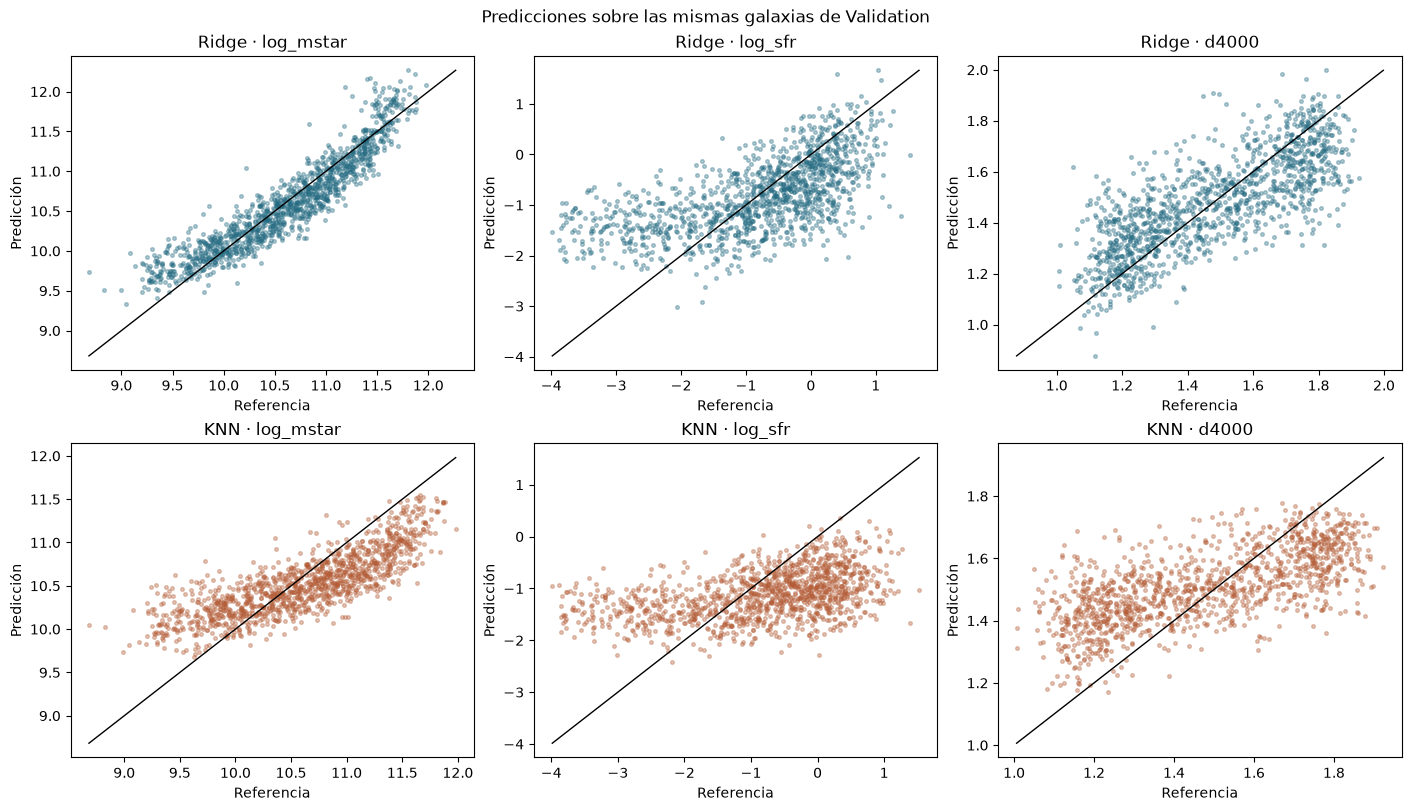

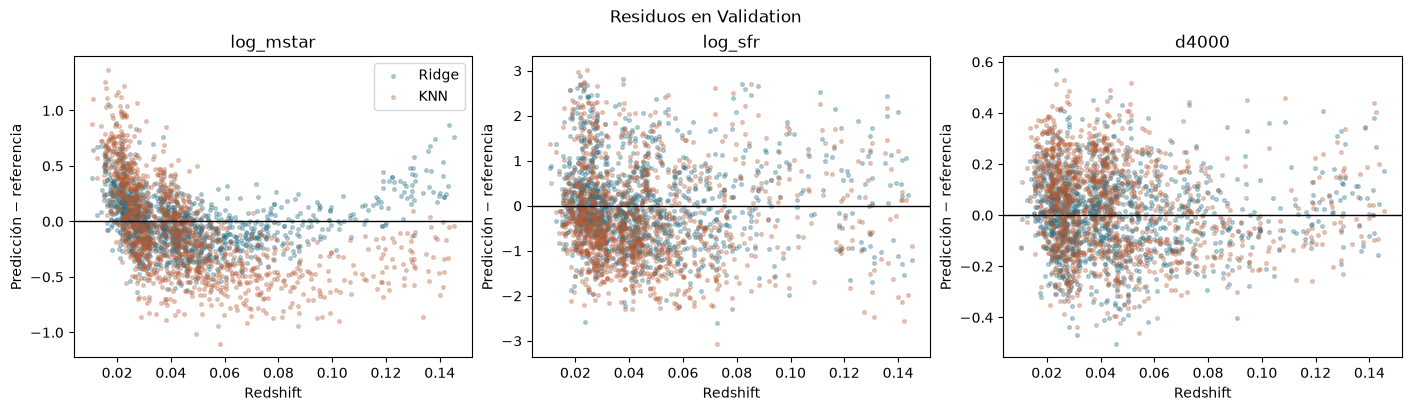

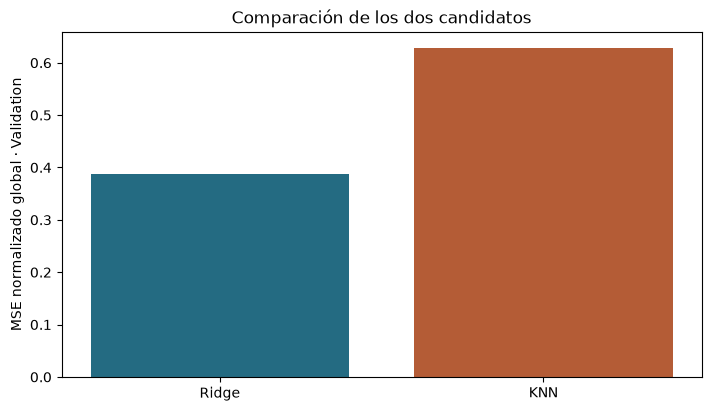

In [15]:
fig,axs=plt.subplots(2,3,figsize=(14,8),layout='constrained')
for fila,nombre in enumerate(MODELOS):
    d=PREDICCIONES[(nombre,'Validation')]
    for j,y in enumerate(OBJETIVOS):
        ax=axs[fila,j];real=d[y];pred=d['pred_'+y]
        lo=min(real.min(),pred.min());hi=max(real.max(),pred.max())
        ax.scatter(real,pred,s=7,alpha=.35,color='#246b82' if nombre=='Ridge' else '#b45c36')
        ax.plot([lo,hi],[lo,hi],color='black',linewidth=1)
        ax.set(title=nombre+' · '+y,xlabel='Referencia',ylabel='Predicción')
fig.suptitle('Predicciones sobre las mismas galaxias de Validation')
fig.savefig(SALIDA/'predicciones_Validation.pdf');plt.show();plt.close(fig)
fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for j,y in enumerate(OBJETIVOS):
    for nombre,color in [('Ridge','#246b82'),('KNN','#b45c36')]:
        d=PREDICCIONES[(nombre,'Validation')]
        axs[j].scatter(d.redshift,d['residuo_'+y],s=7,alpha=.3,label=nombre,color=color)
    axs[j].axhline(0,color='black',linewidth=1)
    axs[j].set(title=y,xlabel='Redshift',ylabel='Predicción − referencia')
axs[0].legend();fig.suptitle('Residuos en Validation')
fig.savefig(SALIDA/'residuos_Validation.pdf');plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.bar(RANKING.modelo,RANKING.MSE_normalizado_global,color=['#246b82','#b45c36'])
ax.set(title='Comparación de los dos candidatos',ylabel='MSE normalizado global · Validation')
fig.savefig(SALIDA/'ranking_Ridge_KNN_Validation.pdf');plt.show();plt.close(fig)


11 · Archivos de la ejecución

Guardamos los resultados en una carpeta independiente, identificada por la configuración, los archivos de origen y las características utilizadas. Podemos recuperar una ejecución completa sin volver a ajustar los modelos. Si cambiamos parámetros, se genera otra identidad de corrida; conservamos los registros de las ejecuciones anteriores.

| Archivo o carpeta | Contenido |
|---|---|
| `protocolo_Ridge_KNN.json` | Parámetros ejecutados, candidatos propuestos, versiones y procedencia de las entradas. |
| `Ridge/modelo.joblib` y `KNN/modelo.joblib` | Estimador, preprocesamiento y escalas para recuperar cada candidato. |
| `Ridge/` y `KNN/` | Predicciones, métricas y registro de cada modelo. |
| `metricas_Ridge_KNN.csv` | Métricas de ambos modelos en Train y Validation. |
| `ranking_Ridge_KNN_Validation.csv` | Comparación global de los dos candidatos nuevos. |
| `comparacion_disponible_Validation.csv` | Métricas de los candidatos y de los otros modelos del equipo. |
| `resultado_comparacion_Ridge_KNN.json` | Mejor resultado entre Ridge y KNN, o registro de empate numérico. |
| `conclusion_Ridge_KNN.md` | Conclusión redactada con los valores calculados en esta ejecución. |

El ZIP incluye tablas, figuras, protocolo y conclusión. Dejamos los archivos de modelos en sus carpetas para contener el tamaño del informe; el ZIP no sustituye esos archivos ni las características de SVR. No generamos resultados de Test.


In [16]:
def tabla_markdown(tabla,columnas):
    texto=['| '+' | '.join(columnas)+' |','|'+'|'.join(['---']*len(columnas))+'|']
    for _,fila in tabla[columnas].iterrows():
        valores=[]
        for col in columnas:
            x=fila[col]
            valores.append(f'{x:.6f}' if isinstance(x,(float,np.floating)) else str(x))
        texto.append('| '+' | '.join(valores)+' |')
    return '\n'.join(texto)


def redactar_conclusion(metricas,ranking,ranking_referencias,n_train,n_val):
    primero,segundo=ranking.iloc[0],ranking.iloc[1]
    a,b=float(primero.MSE_normalizado_global),float(segundo.MSE_normalizado_global)
    empate=bool(np.isclose(a,b,rtol=1e-10,atol=1e-12))
    if empate:
        apertura='Obtuvimos un empate numérico entre Ridge y KNN bajo el criterio global de Validation; no declaramos un ganador único.'
        ganador=None
    else:
        ganador=str(primero.modelo)
        apertura=(f'Entre los dos candidatos de este notebook, obtuvimos el mejor resultado global con {ganador}: '
                  f'su MSE normalizado de Validation fue {a:.6f}, frente a {b:.6f} de {segundo.modelo}. '
                  'Esta diferencia describe el desempeño observado en nuestra partición; no demuestra superioridad en cualquier población.')
    val=metricas.loc[metricas.particion.eq('Validation') & metricas.evaluacion.eq('Validation')]
    lineas=['## Resultado de la comparación entre Ridge y KNN','',apertura,'',
        f'Ajustamos cada algoritmo con las mismas {n_train:,} galaxias de Train y lo evaluamos sobre las mismas {n_val:,} galaxias de Validation. '
        'Reutilizamos el extractor fijo, el PCA, las escalas y el redshift del SVR; no combinamos las predicciones de los modelos.','',
        tabla_markdown(val,['modelo','objetivo','unidad','MAE','RMSE','sesgo','R2','MSE_normalizado']),'',
        'Al revisar cada propiedad por MAE observamos lo siguiente:']
    for objetivo in OBJETIVOS:
        d=val.loc[val.objetivo.eq(objetivo)].sort_values(['MAE','modelo'])
        r0,r1=d.iloc[0],d.iloc[1]
        if np.isclose(r0.MAE,r1.MAE,rtol=1e-10,atol=1e-12):
            lineas.append(f'- {objetivo}: ambos modelos empataron numéricamente en MAE ({r0.MAE:.6f}).')
        else:
            lineas.append(f'- {objetivo}: {r0.modelo} obtuvo el menor MAE ({r0.MAE:.6f} {r0.unidad}).')
    lineas.extend(['','Reunimos los siguientes resultados de Validation:',
        '',tabla_markdown(ranking_referencias,['modelo','MSE_normalizado_global','resultado']),'',
        'Expresamos los errores de masa y SFR en dex; los de D4000 son adimensionales. '
        'La comparación con SVR mantiene las mismas entradas; la comparación con ResNet50, cuando está disponible, incluye diferencias de representación y ajuste del extractor.','',
        'Conservamos Ridge y KNN como candidatos iniciales. Los valores alternativos de sus parámetros quedaron propuestos, '
        'sin atribuirles experimentos que no ejecutamos. A partir de los resultados reunidos, '
        'seleccionaremos los dos mejores y ajustaremos sus hiperparámetros. Elegiremos entonces un único modelo final antes de evaluarlo en Test. '
        'En este notebook no realizamos esa evaluación.'])
    return '\n'.join(lineas),dict(mejor_entre_Ridge_y_KNN=ganador,empate_numerico=empate,
        criterio='MSE normalizado global en Validation',ranking=ranking.to_dict('records'),
        seleccion_final_entre_seis_pendiente=True,evaluacion_test=False)


In [17]:
RESUMEN,SELECCION_PARCIAL=redactar_conclusion(METRICAS,RANKING,RANKING_REFERENCIAS,
                                             len(TABLAS['Train']),len(TABLAS['Validation']))
(SALIDA/'conclusion_Ridge_KNN.md').write_text(RESUMEN,encoding='utf-8')
escribir_json(SELECCION_PARCIAL,SALIDA/'resultado_comparacion_Ridge_KNN.json')
ZIP_RESULTADOS=SALIDA/'resultados_Ridge_KNN_Train_Validation.zip'
with zipfile.ZipFile(ZIP_RESULTADOS,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for ruta in sorted(SALIDA.rglob('*')):
        if ruta.is_file() and ruta.suffix.lower() in {'.csv','.json','.md','.pdf','.png'}:
            z.write(ruta,ruta.relative_to(SALIDA))
print('Métricas, figuras y conclusión:',ZIP_RESULTADOS)
print('Modelos y preprocesamiento:',SALIDA/'Ridge'/'modelo.joblib','y',SALIDA/'KNN'/'modelo.joblib')
try: display(FileLink(os.path.relpath(ZIP_RESULTADOS,Path.cwd())))
except ValueError: pass


Métricas, figuras y conclusión: /home/a01796921/DESI_experimentos_ridge_knn/modelos_05_06_v01/32c9957a9ea988c4/resultados_Ridge_KNN_Train_Validation.zip
Modelos y preprocesamiento: /home/a01796921/DESI_experimentos_ridge_knn/modelos_05_06_v01/32c9957a9ea988c4/Ridge/modelo.joblib y /home/a01796921/DESI_experimentos_ridge_knn/modelos_05_06_v01/32c9957a9ea988c4/KNN/modelo.joblib


/home/a01796921/DESI_experimentos_ridge_knn/modelos_05_06_v01/32c9957a9ea988c4/resultados_Ridge_KNN_Train_Validation.zip

12 · Declaración de IA y referencias de implementación

Utilizamos ChatGPT con el modelo GPT-6 como apoyo para estructurar el código y revisar el procedimiento de comparación. Como equipo, integramos la implementación con las decisiones del proyecto y revisamos las salidas antes de interpretarlas. La incorporación del redshift provino de la sugerencia del Dr. Iván Reyes Amezcua; su tratamiento en el proyecto se discutió con el Dr. Héctor Hernández Toledo y el Dr. José Antonio Vázquez Mata, considerando el origen de las etiquetas y sus correcciones astronómicas. En estos dos candidatos conservamos ese tratamiento y no añadimos nuevas correcciones a las etiquetas.

Utilizamos la documentación de scikit-learn para consultar la definición de los estimadores, sus parámetros y el manejo del preprocesamiento. Las elecciones iniciales de `alpha=1.0` y 15 vecinos pertenecen a nuestro diseño; no las atribuimos a una recomendación óptima de estas fuentes.

- [Regresión Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).
- [Regresión KNN](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html).
- [Separación de entrenamiento y evaluación y prevención de fuga de información](https://scikit-learn.org/stable/common_pitfalls.html).

13 · Resultado de la comparación

La última celda redacta la conclusión con las métricas calculadas y señala qué modelo obtuvo el mejor resultado global en Validation. También distingue el resultado global del menor MAE por propiedad. Si los criterios coinciden dentro de la tolerancia numérica, registra un empate en lugar de declarar un ganador por el orden de las filas. Al guardar el notebook después de ejecutarlo, conservamos esta conclusión junto con sus tablas.


In [18]:
display(Markdown(RESUMEN))


## Resultado de la comparación entre Ridge y KNN

Entre los dos candidatos de este notebook, obtuvimos el mejor resultado global con Ridge: su MSE normalizado de Validation fue 0.387151, frente a 0.627998 de KNN. Esta diferencia describe el desempeño observado en nuestra partición; no demuestra superioridad en cualquier población.

Ajustamos cada algoritmo con las mismas 7,121 galaxias de Train y lo evaluamos sobre las mismas 1,261 galaxias de Validation. Reutilizamos el extractor fijo, el PCA, las escalas y el redshift del SVR; no combinamos las predicciones de los modelos.

| modelo | objetivo | unidad | MAE | RMSE | sesgo | R2 | MSE_normalizado |
|---|---|---|---|---|---|---|---|
| Ridge | log_mstar | dex | 0.189112 | 0.241779 | 0.001057 | 0.864042 | 0.139793 |
| Ridge | log_sfr | dex | 0.711237 | 0.916069 | 0.014512 | 0.380067 | 0.622273 |
| Ridge | d4000 | adimensional | 0.120821 | 0.153374 | 0.001702 | 0.576431 | 0.399388 |
| KNN | log_mstar | dex | 0.350682 | 0.426436 | -0.072025 | 0.577063 | 0.434865 |
| KNN | log_sfr | dex | 0.893574 | 1.083441 | -0.285702 | 0.132842 | 0.870432 |
| KNN | d4000 | adimensional | 0.153836 | 0.184621 | 0.035160 | 0.386263 | 0.578699 |

Al revisar cada propiedad por MAE observamos lo siguiente:
- log_mstar: Ridge obtuvo el menor MAE (0.189112 dex).
- log_sfr: Ridge obtuvo el menor MAE (0.711237 dex).
- d4000: Ridge obtuvo el menor MAE (0.120821 adimensional).

Reunimos los siguientes resultados de Validation:

| modelo | MSE_normalizado_global | resultado |
|---|---|---|
| ResNet50_E_s42 | 0.127879 | Individual |
| DINOv3 | 0.152200 | Media de 3 semillas |
| ConvNeXt_Tiny | 0.162500 | Media de 3 semillas |
| Ridge | 0.387151 | Individual |
| SVR | 0.442091 | Individual |
| KNN | 0.627998 | Individual |

Expresamos los errores de masa y SFR en dex; los de D4000 son adimensionales. La comparación con SVR mantiene las mismas entradas; la comparación con ResNet50, cuando está disponible, incluye diferencias de representación y ajuste del extractor.

Conservamos Ridge y KNN como candidatos iniciales. Los valores alternativos de sus parámetros quedaron propuestos, sin atribuirles experimentos que no ejecutamos. A partir de los resultados reunidos, seleccionaremos los dos mejores y ajustaremos sus hiperparámetros. Elegiremos entonces un único modelo final antes de evaluarlo en Test. En este notebook no realizamos esa evaluación.

## Modelo con mejor resultado en Validation

De acuerdo con el MSE normalizado global, identificamos a ResNet50_E_s42 como el modelo con mejor resultado en la tabla comparativa. Obtuvimos un valor de 0.127879, el menor entre los seis candidatos presentados.

Esta configuración corresponde a la variante E de ResNet50 multitarea, con imágenes GRZ, redshift y pérdida Huber. El resultado pertenece a una sola red entrenada con semilla 42, que predice masa estelar, tasa de formación estelar y D4000 mediante tres cabezas de regresión.

El siguiente resultado más bajo correspondió a DINOv3, con 0.152200 como promedio de las métricas de tres semillas. Por tanto, ResNet50_E_s42 ocupa el primer lugar según el criterio global de Validation utilizado en esta comparación.